In [220]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,r2_score
from sklearn.tree import export_graphviz
import graphviz
from sklearn.ensemble import BaggingRegressor


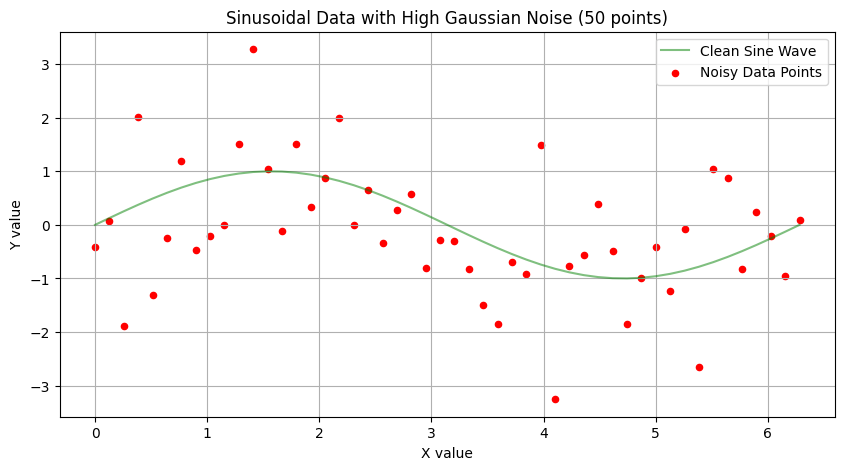

Generated 50 noisy data points (x, y_noisy):
(0.0000, -0.4168)
(0.1282, 0.0716)
(0.2565, -1.8825)
(0.3847, 2.0155)
(0.5129, -1.3027)
(0.6411, -0.2436)
(0.7694, 1.1986)
(0.8976, -0.4635)
(1.0258, -0.2028)
(1.1541, 0.0054)
(1.2823, 1.5101)
(1.4105, 3.2794)
(1.5387, 1.0410)
(1.6670, -0.1225)
(1.7952, 1.5140)
(1.9234, 0.3423)
(2.0517, 0.8675)
(2.1799, 1.9952)
(2.3081, -0.0076)
(2.4363, 0.6573)
(2.5646, -0.3326)
(2.6928, 0.2774)
(2.8210, 0.5717)
(2.9493, -0.7976)
(3.0775, -0.2748)
(3.2057, -0.3003)
(3.3339, -0.8288)
(3.4622, -1.5027)
(3.5904, -1.8551)
(3.7186, -0.6990)
(3.8468, -0.9173)
(3.9751, 1.4911)
(4.1033, -3.2549)
(4.2315, -0.7739)
(4.3598, -0.5680)
(4.4880, 0.3847)
(4.6162, -0.4935)
(4.7444, -1.8437)
(4.8727, -0.9872)
(5.0009, -0.4163)
(5.1291, -1.2279)
(5.2574, -0.0841)
(5.3856, -2.6499)
(5.5138, 1.0355)
(5.6420, 0.8696)
(5.7703, -0.8264)
(5.8985, 0.2361)
(6.0267, -0.2057)
(6.1550, -0.9570)
(6.2832, 0.0877)


In [221]:
N = 50
amplitude = 1
frequency = 1

x = np.linspace(0, 2 * np.pi * frequency, N)
y_clean = amplitude * np.sin(x)

mean = 0
standard_deviation = 1
noise = np.random.normal(mean, standard_deviation, N)

y_noisy = y_clean + noise

plt.figure(figsize=(10, 5))
plt.plot(x, y_clean, color='green', label='Clean Sine Wave', alpha=0.5)
plt.scatter(x, y_noisy, color='red', label='Noisy Data Points', s=20)
plt.title('Sinusoidal Data with High Gaussian Noise (50 points)')
plt.xlabel('X value')
plt.ylabel('Y value')
plt.legend()
plt.grid(True)
plt.show()

print(f"Generated {N} noisy data points (x, y_noisy):")
for i in range(N):
    print(f"({x[i]:.4f}, {y_noisy[i]:.4f})")


In [222]:
SEED=2
np.random.seed(SEED)
df = pd.DataFrame({'x': x, 'y': y_noisy})
display(df)

,x,y
0,0.000000,-0.416758
1,0.128228,0.071610
2,0.256457,-1.882542
3,0.384685,2.015538
4,0.512913,-1.302718
5,0.641141,-0.243637
6,0.769370,1.198564
7,0.897598,-0.463457
8,1.025826,-0.202809
9,1.154054,0.005405


In [223]:
x_train, x_test, y_train, y_test = train_test_split(x, y_noisy, test_size=0.2, random_state=2)
x_train = x_train.reshape(-1, 1)
x_test = x_test.reshape(-1, 1)

Desicion Tree:

In [224]:
dtree=DecisionTreeRegressor(random_state=2,max_depth = None)

dtree.fit(x_train, y_train)

print(r2_score(x_train, y_train))

-4.126012384870624


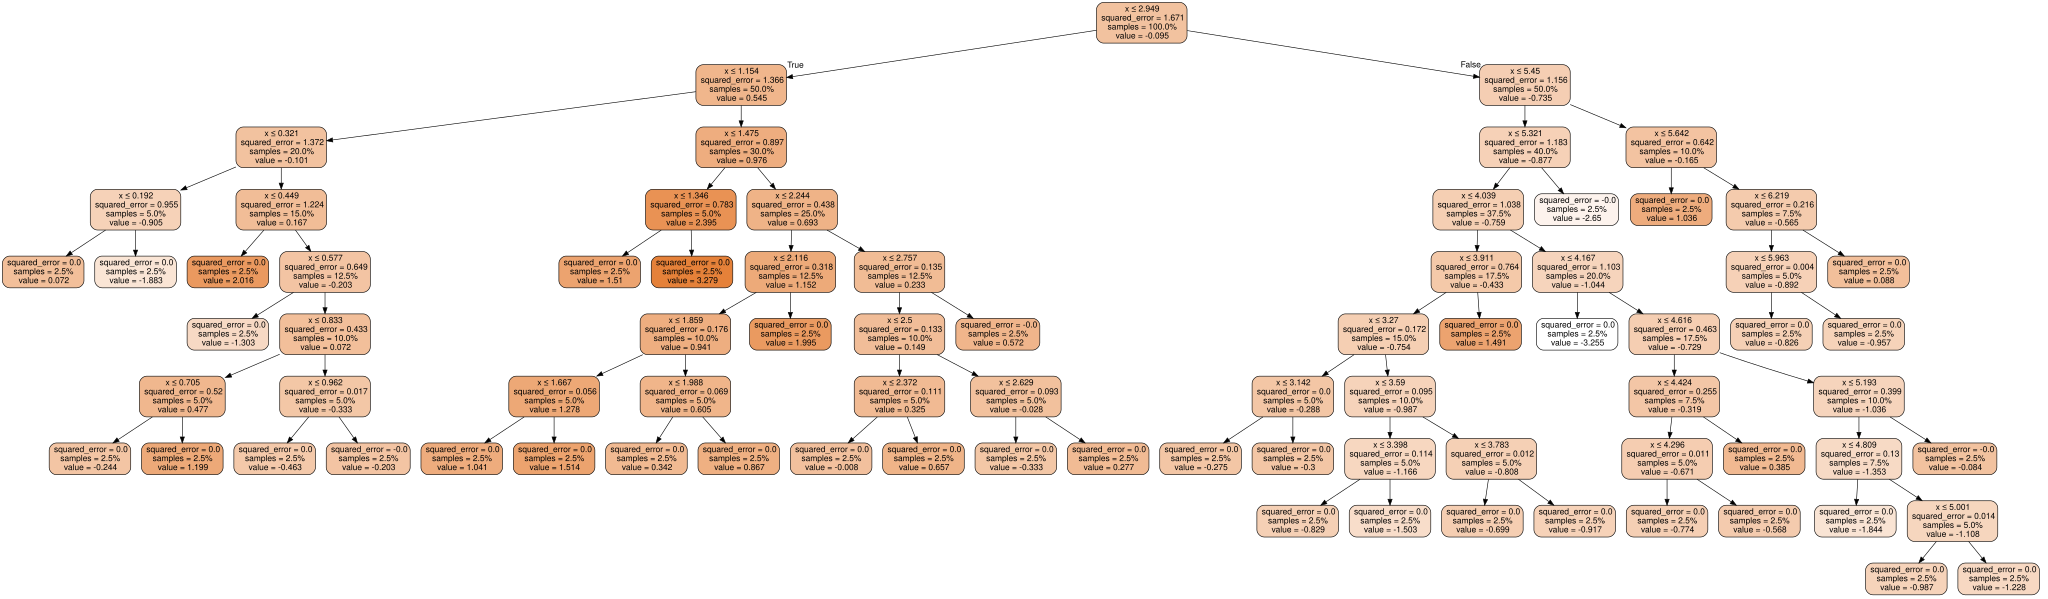

In [225]:
feature_names = ['x']
dot_data = export_graphviz(
    dtree,
    out_file=None,
    feature_names=feature_names,
    filled=True,
    rounded=True,
    special_characters=True,
    proportion=True
)

dot_data = dot_data.replace('digraph Tree {', 'digraph Tree {\n  size="300,10!";')
graph = graphviz.Source(dot_data, format='png', engine='dot')
graph

In [226]:
y_pred_tree = dtree.predict(x_test)
r2_tree = r2_score(y_test, y_pred_tree)

print(f"R-squared on test set: {r2_tree}")

R-squared on test set: -0.4290206437541093


In [227]:
mse_tree = mean_squared_error(y_test, y_pred_tree)
print(f"MSE: {mse_tree}")


MSE: 0.645293840249774


Begging Regressor:

In [228]:
bagging_regressor = BaggingRegressor(estimator=dtree, n_estimators=100, random_state=2)
bagging_regressor.fit(x_train, y_train)

BaggingRegressor(estimator=DecisionTreeRegressor(random_state=2),
                 n_estimators=100, random_state=2)

In [229]:
y_pred_bag_reg = bagging_regressor.predict(x_test)

r2_bag_reg = r2_score(y_test, y_pred_bag_reg)
print(f"R-squared on test set: {r2_bag_reg}")

mse_bag_reg = mean_squared_error(y_test, y_pred_bag_reg)
print(f"MSE: {mse_bag_reg}")


R-squared on test set: -0.40785071885034685
MSE: 0.635734270765137


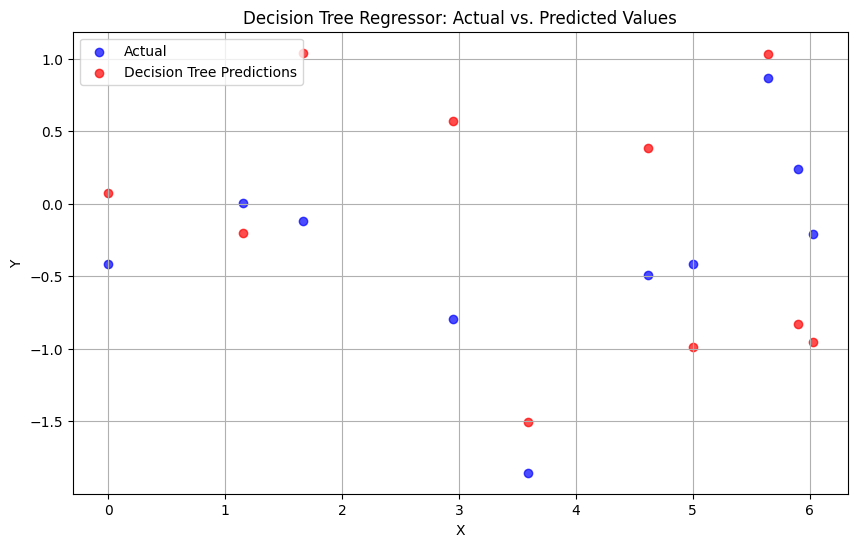

In [230]:
plt.figure(figsize=(10, 6))
plt.scatter(x_test, y_test, color='blue', label='Actual', alpha=0.7)
plt.scatter(x_test, y_pred_tree, color='red', label='Decision Tree Predictions', alpha=0.7)
plt.title('Decision Tree Regressor: Actual vs. Predicted Values')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True)
plt.show()

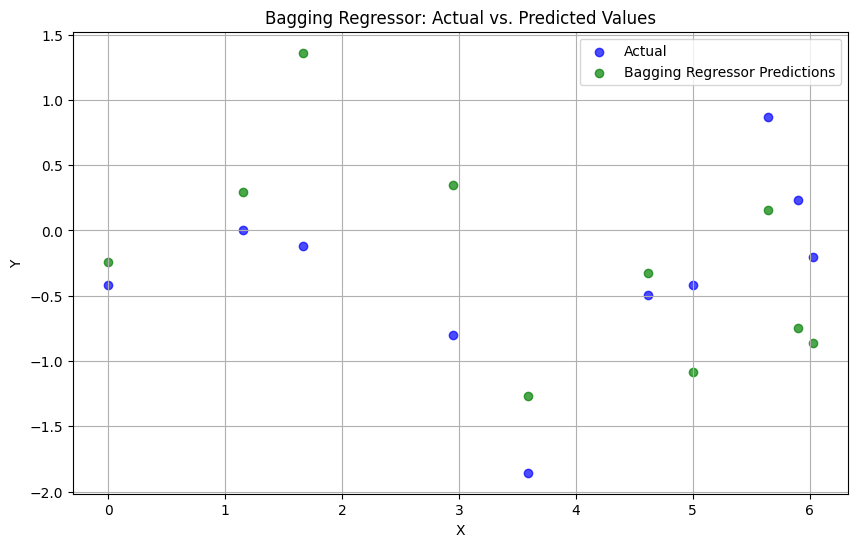

In [231]:
plt.figure(figsize=(10, 6))
plt.scatter(x_test, y_test, color='blue', label='Actual', alpha=0.7)
plt.scatter(x_test, y_pred_bag_reg, color='green', label='Bagging Regressor Predictions', alpha=0.7)
plt.title('Bagging Regressor: Actual vs. Predicted Values')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True)
plt.show()

In [232]:
model_summary = [
    {
        'Model': 'Decision Tree',
        'R-squared': r2_tree,
        'MSE': mse_tree
    },
    {
        'Model': 'Bagging Regressor',
        'R-squared': r2_bag_reg,
        'MSE': mse_bag_reg
    }]
summary_df = pd.DataFrame(model_summary)
display(summary_df)

,Model,R-squared,MSE
0,Decision Tree,-0.429021,0.645294
1,Bagging Regressor,-0.407851,0.635734
